In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('credit_risk_dataset.csv')


In [ ]:
# Inspect the dataset shape
print(f"Dataset shape: {df.shape}")

Dataset shape: (32581, 11)


In [ ]:
# Inspect the column names
print("Dataset columns:")
print(df.columns)

Dataset columns:
Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_amnt', 'loan_int_rate',
       'loan_status', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length'],
      dtype='object')


In [ ]:
# Display the first few rows of the DataFrame to understand each feature
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


In [ ]:
# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_amnt                   32581 non-null  int64  
 6   loan_int_rate               29465 non-null  float64
 7   loan_status                 32581 non-null  int64  
 8   loan_percent_income         32581 non-null  float64
 9   cb_person_default_on_file   32581 non-null  object 
 10  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 2.7+ MB


In [ ]:
# Calculate the number of missing values per column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values per column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create a DataFrame to display missing values
missing_info = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentage
})

# Filter to show only columns with missing values and sort
missing_info = missing_info[missing_info['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Missing Values by Column:")
print(missing_info)

Missing Values by Column:
                   Missing Count  Missing Percentage
loan_int_rate               3116            9.563856
person_emp_length            895            2.747000


In [ ]:
# Describe numerical features
print("Statistical Description of Numerical Features:")
df.describe()

Statistical Description of Numerical Features:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
# Describe categorical features
print("Statistical Description of Categorical Features:")
df.describe(include='object')

Statistical Description of Categorical Features:


,person_home_ownership,loan_intent,cb_person_default_on_file
count,32581,32581,32581
unique,4,6,2
top,RENT,EDUCATION,N
freq,16446,6453,26836


In [ ]:
# Get list of categorical columns
categorical_cols = df.select_dtypes(include='object').columns

print("Unique Values and Counts for Categorical Features:")
for col in categorical_cols:
    print(f"\n--- Column: {col} ---")
    print(df[col].value_counts())
    print(f"Number of unique values: {df[col].nunique()}")

Unique Values and Counts for Categorical Features:

--- Column: person_home_ownership ---
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64
Number of unique values: 4

--- Column: loan_intent ---
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64
Number of unique values: 6

--- Column: cb_person_default_on_file ---
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64
Number of unique values: 2


In [ ]:
# Capping 'person_age' outliers
# Based on general human lifespan and the dataset's overall age distribution
max_reasonable_age = 80
df['person_age'] = df['person_age'].apply(lambda x: min(x, max_reasonable_age))

# Capping 'person_emp_length' outliers
# Based on a realistic maximum employment span
max_reasonable_emp_length = 60
df['person_emp_length'] = df['person_emp_length'].apply(lambda x: min(x, max_reasonable_emp_length))

print("Outliers in 'person_age' and 'person_emp_length' have been capped.")

# Verify the changes by re-describing the relevant columns
print("\nUpdated statistical description for 'person_age' and 'person_emp_length':")
print(df[['person_age', 'person_emp_length']].describe())

Outliers in 'person_age' and 'person_emp_length' have been capped.

Updated statistical description for 'person_age' and 'person_emp_length':
         person_age  person_emp_length
count  32581.000000       31686.000000
mean      27.725515           4.785710
std        6.233069           4.058539
min       20.000000           0.000000
25%       23.000000           2.000000
50%       26.000000           4.000000
75%       30.000000           7.000000
max       80.000000          60.000000


In [ ]:
# Impute missing values in 'person_emp_length' with its median
median_emp_length = df['person_emp_length'].median()
df['person_emp_length'] = df['person_emp_length'].fillna(median_emp_length)

# Impute missing values in 'loan_int_rate' with its median
median_int_rate = df['loan_int_rate'].median()
df['loan_int_rate'] = df['loan_int_rate'].fillna(median_int_rate)

print("Missing values in 'person_emp_length' and 'loan_int_rate' have been imputed with their medians.")

# Verify that there are no more missing values in these columns
print("\nVerification of missing values after imputation:")
print(df[['person_emp_length', 'loan_int_rate']].isnull().sum())

Missing values in 'person_emp_length' and 'loan_int_rate' have been imputed with their medians.

Verification of missing values after imputation:
person_emp_length    0
loan_int_rate        0
dtype: int64


In [ ]:
# Calculate the number of duplicate rows
initial_row_count = len(df)
duplicate_rows = df.duplicated().sum()

print(f"Initial number of rows: {initial_row_count}")
print(f"Number of duplicate rows found: {duplicate_rows}")

if duplicate_rows > 0:
    # Remove duplicate rows
    df.drop_duplicates(inplace=True)
    final_row_count = len(df)
    print(f"Duplicate rows removed. Final number of rows: {final_row_count}")
    print(f"Rows removed: {initial_row_count - final_row_count}")
else:
    print("No duplicate rows found.")

Initial number of rows: 32581
Number of duplicate rows found: 165
Duplicate rows removed. Final number of rows: 32416
Rows removed: 165


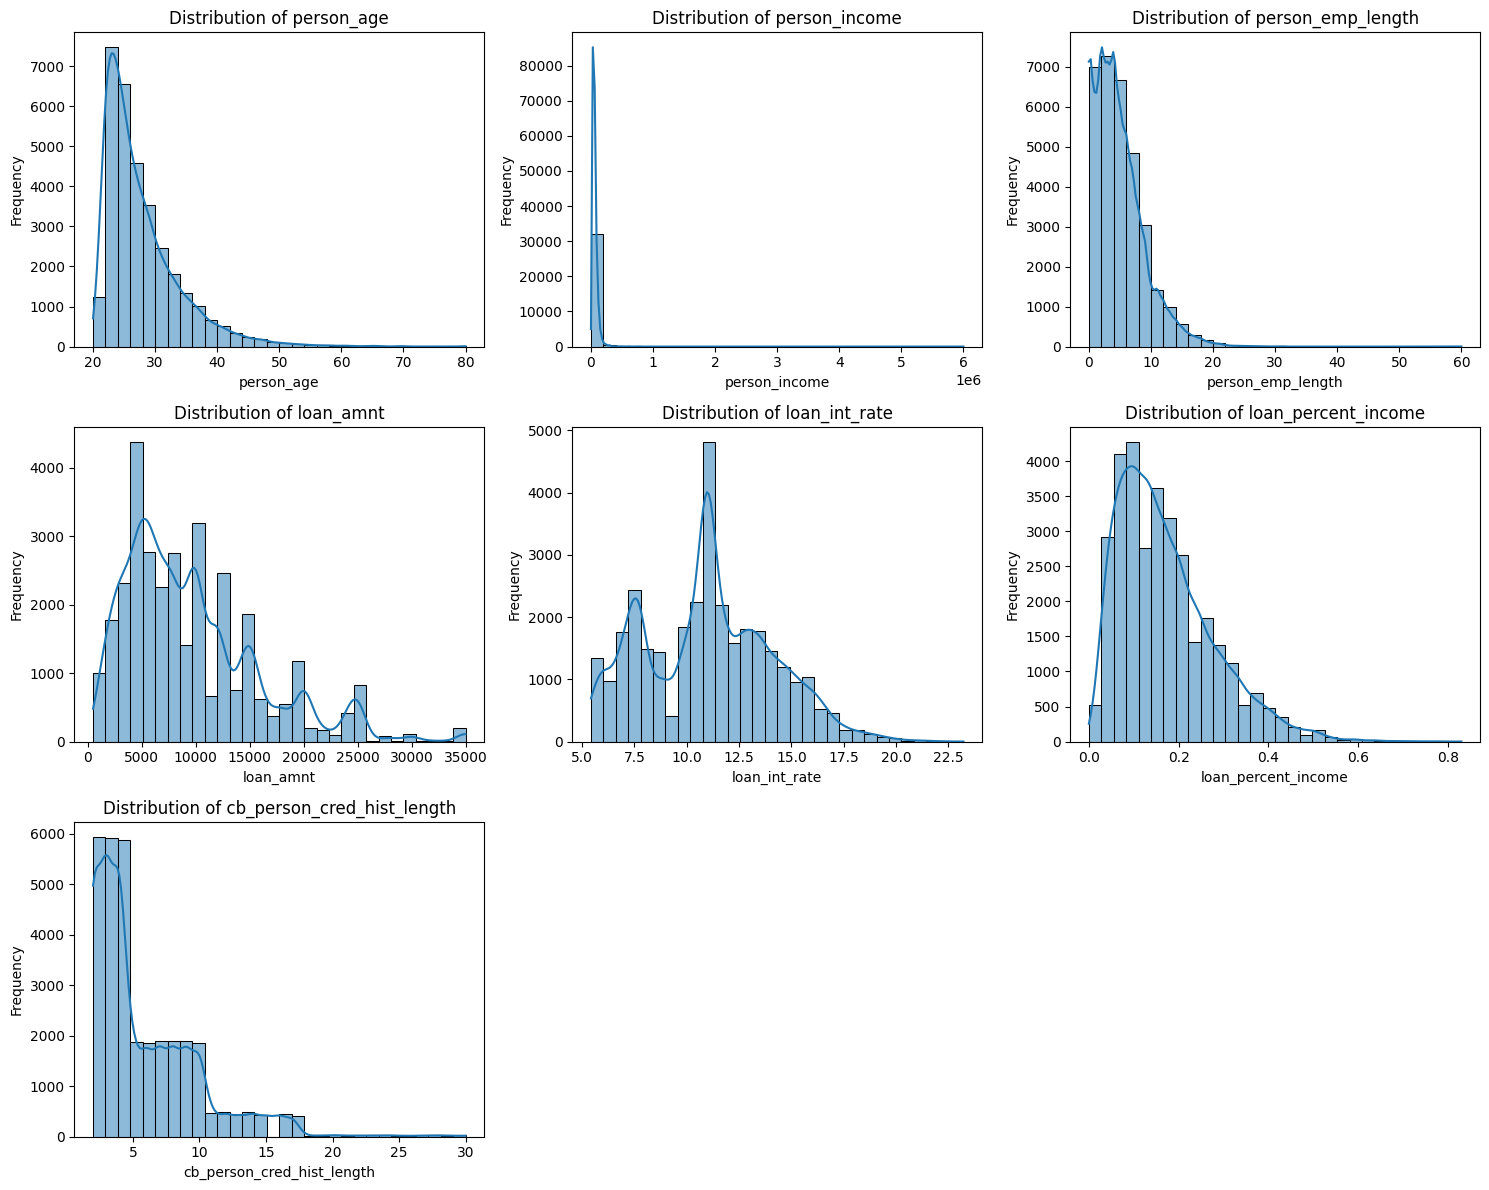

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for plotting histograms
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Exclude 'loan_status' as it's our target variable and we'll analyze it separately
if 'loan_status' in numerical_cols:
    numerical_cols.remove('loan_status')

# Determine the number of rows and columns for the subplot grid
num_numerical_cols = len(numerical_cols)
num_cols = 3  # For example, 3 columns per row
num_rows = (num_numerical_cols + num_cols - 1) // num_cols

plt.figure(figsize=(num_cols * 5, num_rows * 4))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


/tmp/ipykernel_573/4077675799.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')
/tmp/ipykernel_573/4077675799.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')
/tmp/ipykernel_573/4077675799.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


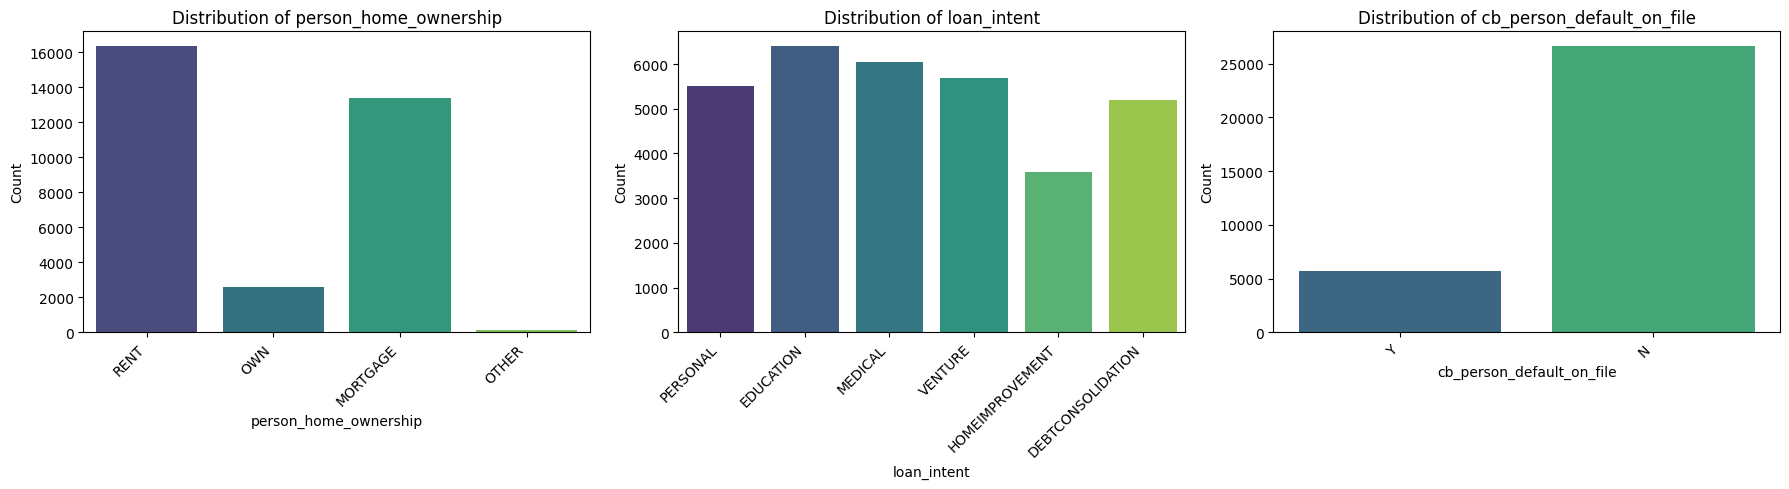

In [ ]:
# Select only categorical columns for plotting count plots
categorical_cols = df.select_dtypes(include='object').columns.tolist()

# Determine the number of rows and columns for the subplot grid
num_categorical_cols = len(categorical_cols)
num_cols = 3  # For example, 3 columns per row
num_rows = (num_categorical_cols + num_cols - 1) // num_cols

plt.figure(figsize=(num_cols * 6, num_rows * 5))
for i, col in enumerate(categorical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right') # Rotate labels for better readability

plt.tight_layout()
plt.show()

/tmp/ipykernel_573/4258235732.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='loan_status', palette='coolwarm')


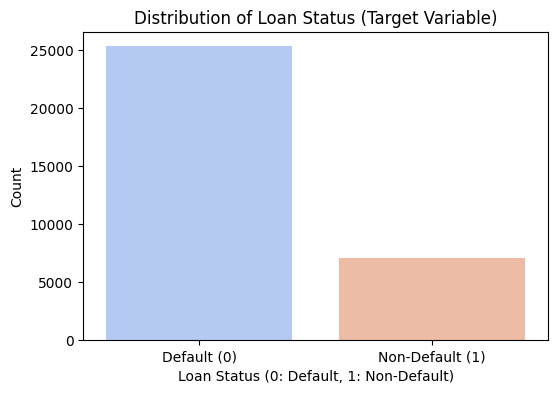


Loan Status Counts:
loan_status
0    25327
1     7089
Name: count, dtype: int64

Loan Status Percentage:
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


In [ ]:
# Visualize the distribution of the target variable 'loan_status'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='loan_status', palette='coolwarm')
plt.title('Distribution of Loan Status (Target Variable)')
plt.xlabel('Loan Status (0: Default, 1: Non-Default)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Default (0)', 'Non-Default (1)'], rotation=0)
plt.show()

# Print the exact counts and percentages
loan_status_counts = df['loan_status'].value_counts()
loan_status_percentage = df['loan_status'].value_counts(normalize=True) * 100

print("\nLoan Status Counts:")
print(loan_status_counts)
print("\nLoan Status Percentage:")
print(loan_status_percentage)

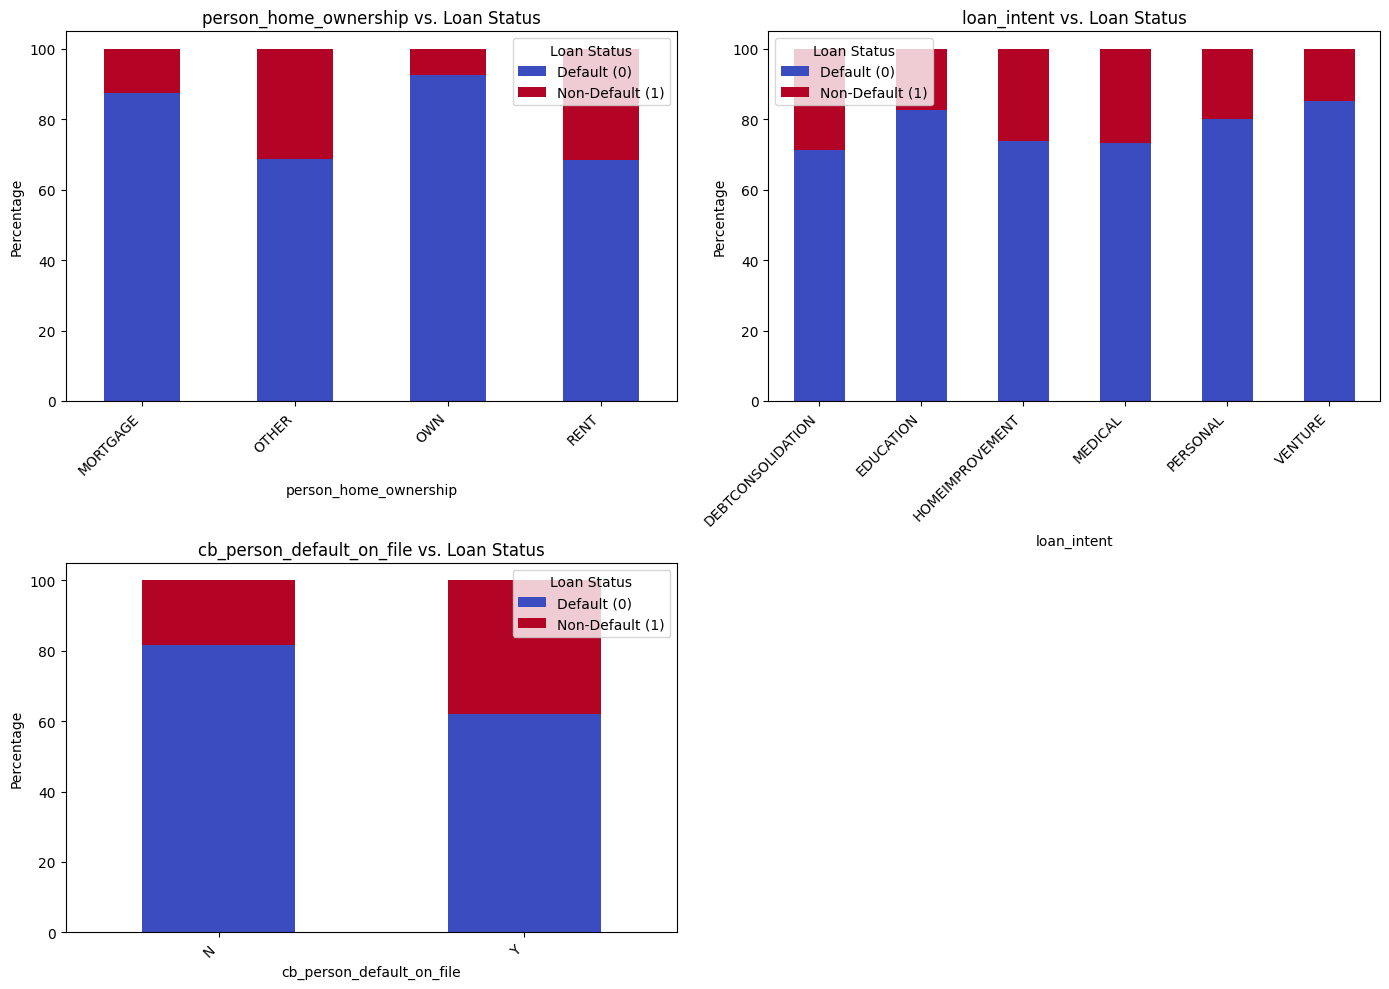

In [ ]:
# Select categorical columns for analysis against the target variable
categorical_cols = df.select_dtypes(include='object').columns.tolist()

# Determine the number of rows and columns for the subplot grid
num_categorical_cols = len(categorical_cols)
num_cols = 2  # Display 2 plots per row for better visibility
num_rows = (num_categorical_cols + num_cols - 1) // num_cols

plt.figure(figsize=(num_cols * 7, num_rows * 5))

for i, col in enumerate(categorical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    # Create a cross-tabulation (contingency table) of the two variables
    cross_tab = pd.crosstab(df[col], df['loan_status'], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, ax=plt.gca(), cmap='coolwarm')
    plt.title(f'{col} vs. Loan Status')
    plt.xlabel(col)
    plt.ylabel('Percentage')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Loan Status', labels=['Default (0)', 'Non-Default (1)'])

plt.tight_layout()
plt.show()

/tmp/ipykernel_573/96862341.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='coolwarm')
/tmp/ipykernel_573/96862341.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='coolwarm')
/tmp/ipykernel_573/96862341.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='coolwarm')
/tmp/ipykernel_573/96862341.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assig

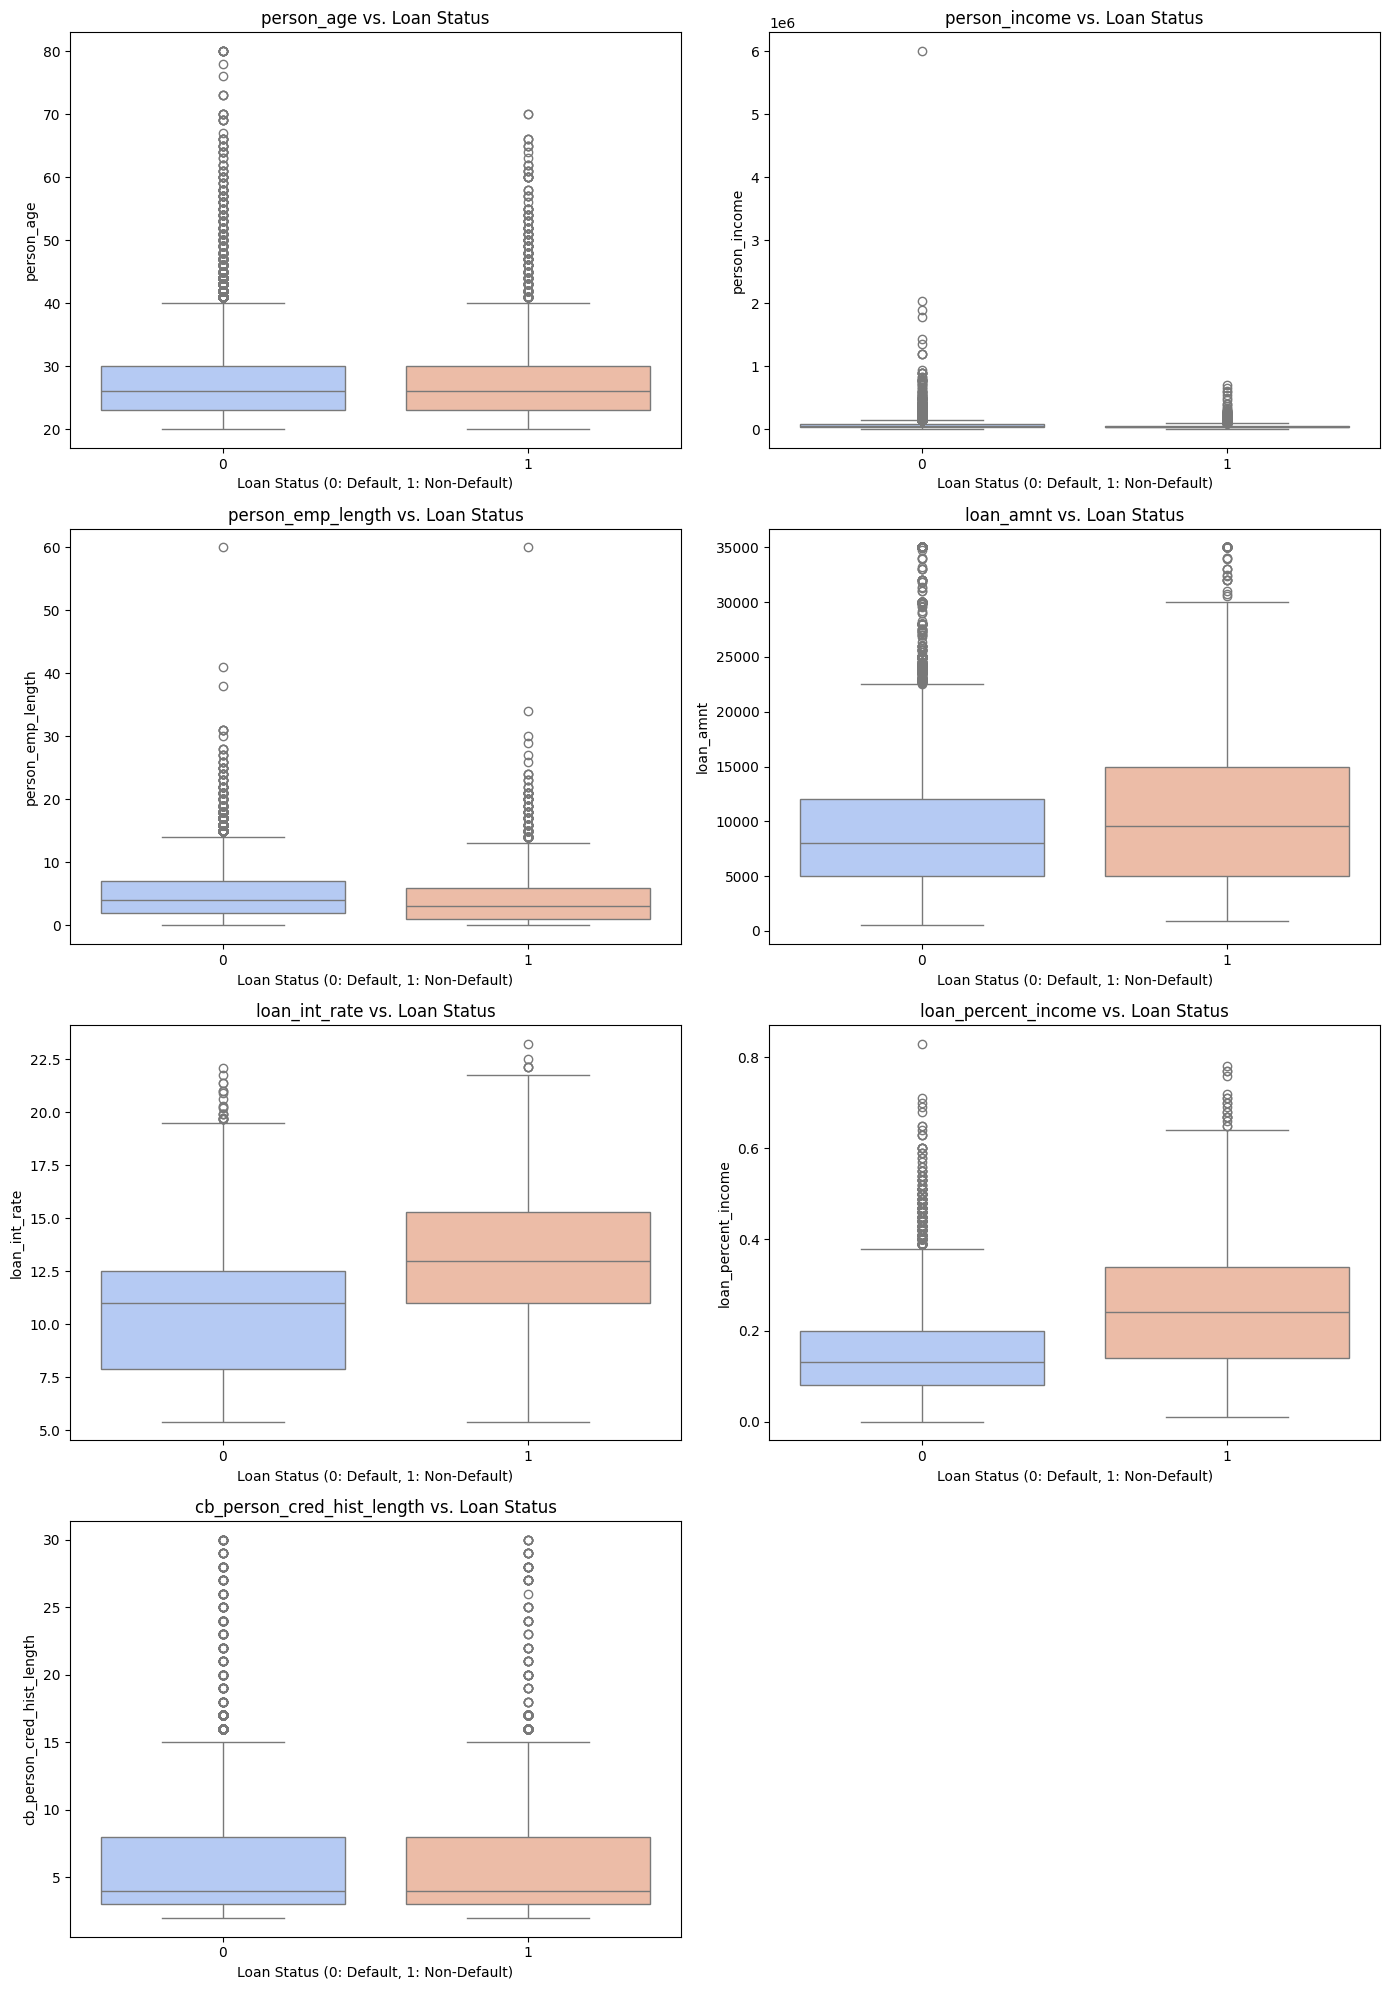

In [ ]:
# Select numerical columns for analysis against the target variable
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Exclude 'loan_status' itself from the features to be plotted against the target
if 'loan_status' in numerical_cols:
    numerical_cols.remove('loan_status')

# Determine the number of rows and columns for the subplot grid
num_numerical_cols = len(numerical_cols)
num_cols = 2  # Display 2 plots per row for better visibility
num_rows = (num_numerical_cols + num_cols - 1) // num_cols

plt.figure(figsize=(num_cols * 7, num_rows * 5))

for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1)
    sns.boxplot(data=df, x='loan_status', y=col, palette='coolwarm')
    plt.title(f'{col} vs. Loan Status')
    plt.xlabel('Loan Status (0: Default, 1: Non-Default)')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

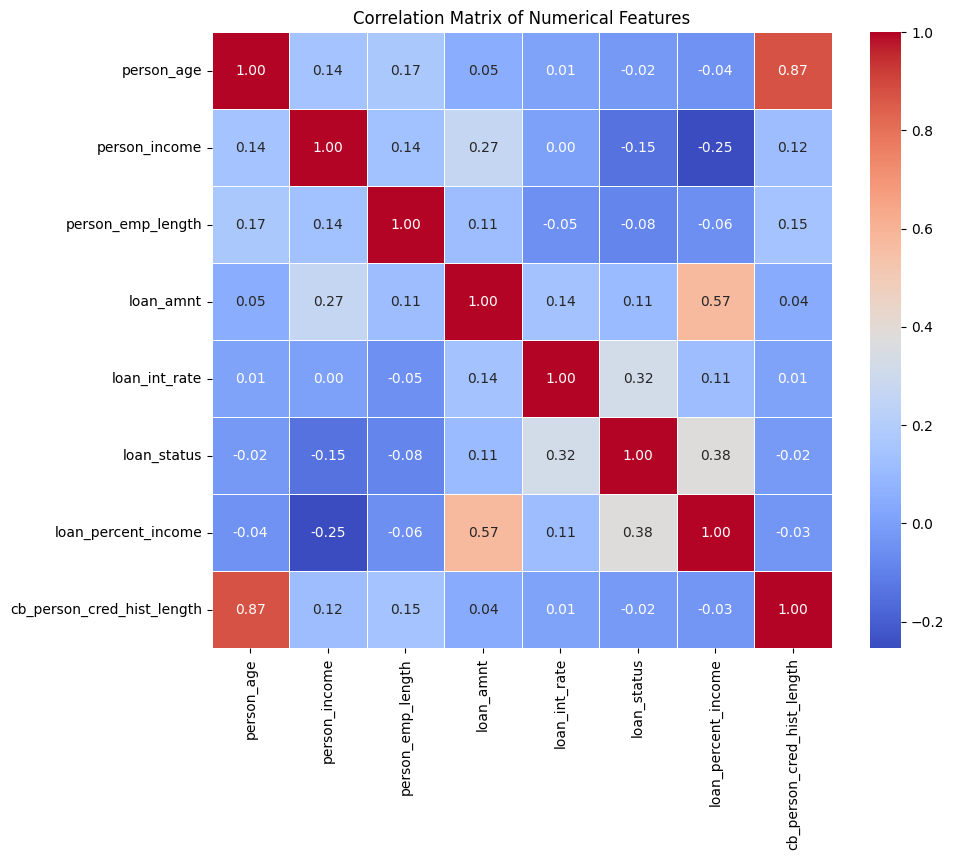

In [ ]:
# Select only numerical columns for correlation analysis
numerical_cols_for_corr = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Calculate the correlation matrix
correlation_matrix = df[numerical_cols_for_corr].corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [ ]:
# Identify numerical features (excluding the target)
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'loan_status' in numerical_features:
    numerical_features.remove('loan_status')

# Identify categorical features
categorical_features = df.select_dtypes(include='object').columns.tolist()

# Identify binary categorical features (if any)
binary_features = [col for col in categorical_features if df[col].nunique() == 2]

# Identify multi-category features
multi_category_features = [col for col in categorical_features if df[col].nunique() > 2]

# Target variable
target_variable = 'loan_status'

print(f"Numerical Features: {numerical_features}")
print(f"Categorical Features: {categorical_features}")
print(f"Binary Categorical Features: {binary_features}")
print(f"Multi-Category Features: {multi_category_features}")
print(f"Target Variable: {target_variable}")

Numerical Features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical Features: ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']
Binary Categorical Features: ['cb_person_default_on_file']
Multi-Category Features: ['person_home_ownership', 'loan_intent']
Target Variable: loan_status


In [ ]:
# 1. Encode binary categorical feature 'cb_person_default_on_file'
# Map 'Y' to 1 and 'N' to 0
df['cb_person_default_on_file'] = df['cb_person_default_on_file'].map({'Y': 1, 'N': 0})

# 2. One-Hot Encode multi-category features
# Use pd.get_dummies for 'person_home_ownership' and 'loan_intent'
df = pd.get_dummies(df, columns=multi_category_features, drop_first=False)

print("Categorical features have been encoded.")
print("Updated DataFrame head after encoding:")
print(df.head())
print("\nUpdated DataFrame info to check dtypes:")
df.info()

Categorical features have been encoded.
Updated DataFrame head after encoding:
   person_age  person_income  person_emp_length  loan_amnt  loan_int_rate  \
0          22          59000               60.0      35000          16.02   
1          21           9600                5.0       1000          11.14   
2          25           9600                1.0       5500          12.87   
3          23          65500                4.0      35000          15.23   
4          24          54400                8.0      35000          14.27   

   loan_status  loan_percent_income  cb_person_default_on_file  \
0            1                 0.59                          1   
1            0                 0.10                          0   
2            1                 0.57                          0   
3            1                 0.53                          0   
4            1                 0.55                          1   

   cb_person_cred_hist_length  person_home_ownership_MORTGAGE

In [ ]:
import numpy as np

# List of numerical features identified as skewed during EDA
skewed_numerical_features = [
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

print("Applying log1p transformation to skewed numerical features...")
for col in skewed_numerical_features:
    # Apply log1p transformation
    df[col] = np.log1p(df[col])
    print(f"  - Transformed '{col}'")

print("\nNumerical features have been transformed.")
print("Updated DataFrame head after transformation:")
print(df.head())
print("\nUpdated statistical description for transformed features:")
print(df[skewed_numerical_features].describe())

Applying log1p transformation to skewed numerical features...
  - Transformed 'person_income'
  - Transformed 'person_emp_length'
  - Transformed 'loan_amnt'
  - Transformed 'loan_percent_income'
  - Transformed 'cb_person_cred_hist_length'

Numerical features have been transformed.
Updated DataFrame head after transformation:
   person_age  person_income  person_emp_length  loan_amnt  loan_int_rate  \
0          22      10.985310           4.110874  10.463132          16.02   
1          21       9.169623           1.791759   6.908755          11.14   
2          25       9.169623           0.693147   8.612685          12.87   
3          23      11.089821           1.609438  10.463132          15.23   
4          24      10.904138           2.197225  10.463132          14.27   

   loan_status  loan_percent_income  cb_person_default_on_file  \
0            1             0.463734                          1   
1            0             0.095310                          0   
2         

In [ ]:
from sklearn.preprocessing import StandardScaler

# Re-identify numerical features, ensuring 'loan_status' is not included
numerical_features_for_scaling = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'loan_status' in numerical_features_for_scaling:
    numerical_features_for_scaling.remove('loan_status')

# Initialize the StandardScaler
scaler = StandardScaler()

print("Applying Standard Scaling to numerical features...")
# Apply scaling to the identified numerical features
# Note: In a real-world scenario with train-test split, the scaler would be fit ONLY on training data
# and then used to transform both training and test data to prevent data leakage.
df[numerical_features_for_scaling] = scaler.fit_transform(df[numerical_features_for_scaling])

print("Numerical features have been scaled.")
print("Updated DataFrame head after scaling:")
print(df.head())
print("\nUpdated statistical description for scaled features (should have mean ~0 and std ~1):")
print(df[numerical_features_for_scaling].describe())

Applying Standard Scaling to numerical features...
Numerical features have been scaled.
Updated DataFrame head after scaling:
   person_age  person_income  person_emp_length  loan_amnt  loan_int_rate  \
0   -0.919748       0.105432           3.367770   2.138606       1.623527   
1   -1.080042      -3.103640           0.389687  -2.859445       0.040655   
2   -0.438865      -3.103640          -1.021093  -0.463433       0.601796   
3   -0.759454       0.290146           0.155559   2.138606       1.367283   
4   -0.599160      -0.038032           0.910363   2.138606       1.055898   

   loan_status  loan_percent_income  cb_person_default_on_file  \
0            1             3.531791                   2.158065   
1            0            -0.659205                  -0.463378   
2            1             3.387795                  -0.463378   
3            1             3.094218                  -0.463378   
4            1             3.241954                   2.158065   

   cb_person_c

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df.drop('loan_status', axis=1)
y = df['loan_status']

print(f"Shape of X before splitting: {X.shape}")
print(f"Shape of y before splitting: {y.shape}")
print(f"Original target distribution:\n{y.value_counts(normalize=True)}\n")

# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

print(f"\nTarget distribution in y_train:\n{y_train.value_counts(normalize=True)}\n")
print(f"Target distribution in y_test:\n{y_test.value_counts(normalize=True)}\n")

Shape of X before splitting: (32416, 18)
Shape of y before splitting: (32416,)
Original target distribution:
loan_status
0    0.781312
1    0.218688
Name: proportion, dtype: float64

Shape of X_train: (25932, 18)
Shape of X_test: (6484, 18)
Shape of y_train: (25932,)
Shape of y_test: (6484,)

Target distribution in y_train:
loan_status
0    0.781313
1    0.218687
Name: proportion, dtype: float64

Target distribution in y_test:
loan_status
0    0.781308
1    0.218692
Name: proportion, dtype: float64



In [ ]:
from imblearn.over_sampling import SMOTE

print(f"Original training set shape: {X_train.shape}, {y_train.shape}")
print(f"Original training target distribution:\n{y_train.value_counts(normalize=True)}\n")

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to the training data only
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Resampled training set shape: {X_train_resampled.shape}, {y_train_resampled.shape}")
print(f"Resampled training target distribution:\n{y_train_resampled.value_counts(normalize=True)}\n")

print("Class imbalance in the training data has been addressed using SMOTE.")

Original training set shape: (25932, 18), (25932,)
Original training target distribution:
loan_status
0    0.781313
1    0.218687
Name: proportion, dtype: float64

Resampled training set shape: (40522, 18), (40522,)
Resampled training target distribution:
loan_status
0    0.5
1    0.5
Name: proportion, dtype: float64

Class imbalance in the training data has been addressed using SMOTE.


In [ ]:
from sklearn.linear_model import LogisticRegression

print("Training a Logistic Regression baseline model...")

# Initialize Logistic Regression model
# Set class_weight='balanced' even though we've SMOTEd, it's good practice for robust models
# For simplicity, we'll keep default parameters for now
logistic_model = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced', max_iter=1000)

# Train the model on the SMOTE-resampled training data
logistic_model.fit(X_train_resampled, y_train_resampled)

print("Logistic Regression baseline model trained successfully!")

Training a Logistic Regression baseline model...
Logistic Regression baseline model trained successfully!


Evaluating Logistic Regression baseline model...

--- Confusion Matrix ---


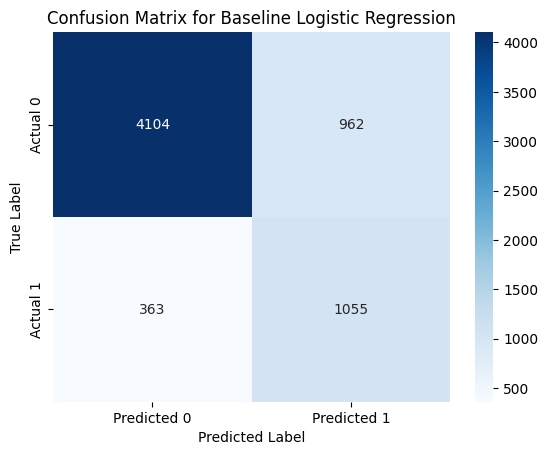


--- Classification Report ---
                 precision    recall  f1-score   support

    Default (0)       0.92      0.81      0.86      5066
Non-Default (1)       0.52      0.74      0.61      1418

       accuracy                           0.80      6484
      macro avg       0.72      0.78      0.74      6484
   weighted avg       0.83      0.80      0.81      6484


--- ROC AUC Score ---
ROC AUC Score: 0.8568
Baseline model evaluation complete.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

print("Evaluating Logistic Regression baseline model...")

# Make predictions on the test set
y_pred = logistic_model.predict(X_test)
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1] # Probability of class 1 (Non-Default)

print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Baseline Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Default (0)', 'Non-Default (1)']))

print("\n--- ROC AUC Score ---")
# Calculate ROC AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

print("Baseline model evaluation complete.")

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Training a Random Forest Classifier model...")

# Initialize Random Forest Classifier
# Using default parameters for now; will tune later if needed.
# n_estimators: number of trees in the forest
# random_state: for reproducibility
# class_weight: 'balanced' helps with imbalance, though we've already used SMOTE
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train the model on the SMOTE-resampled training data
rf_model.fit(X_train_resampled, y_train_resampled)

print("Random Forest Classifier model trained successfully!")

Training a Random Forest Classifier model...
Random Forest Classifier model trained successfully!


Evaluating Random Forest Classifier model...

--- Confusion Matrix for Random Forest ---


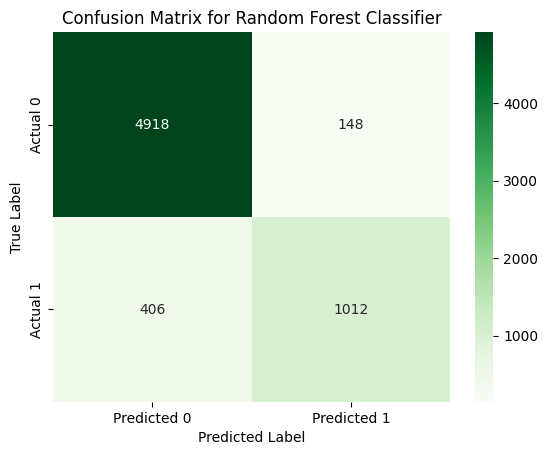


--- Classification Report for Random Forest ---
                 precision    recall  f1-score   support

    Default (0)       0.92      0.97      0.95      5066
Non-Default (1)       0.87      0.71      0.79      1418

       accuracy                           0.91      6484
      macro avg       0.90      0.84      0.87      6484
   weighted avg       0.91      0.91      0.91      6484


--- ROC AUC Score for Random Forest ---
ROC AUC Score: 0.9214
Random Forest model evaluation complete.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

print("Evaluating Random Forest Classifier model...")

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1] # Probability of class 1 (Non-Default)

print("\n--- Confusion Matrix for Random Forest ---")
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Random Forest Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Classification Report for Random Forest ---")
print(classification_report(y_test, y_pred_rf, target_names=['Default (0)', 'Non-Default (1)']))

print("\n--- ROC AUC Score for Random Forest ---")
# Calculate ROC AUC score
roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
print(f"ROC AUC Score: {roc_auc_rf:.4f}")

print("Random Forest model evaluation complete.")

In [ ]:
from sklearn.model_selection import GridSearchCV

print("Starting Hyperparameter Tuning for Random Forest Classifier using GridSearchCV...")

# Define the parameter grid to search
# We'll start with a relatively small grid to manage computational time.
param_grid = {
    'n_estimators': [100, 200, 300],  # Number of trees in the forest
    'max_depth': [10, 20, None],      # Maximum depth of the tree (None means unlimited)
    'min_samples_split': [2, 5],      # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2],       # Minimum number of samples required to be at a leaf node
    'max_features': ['sqrt', 'log2']  # Number of features to consider at each split
}

# Initialize the Random Forest Classifier with class_weight='balanced'
# We use 'balanced' because our original training data (before SMOTE) was imbalanced
# Even with SMOTE, it helps ensure the model doesn't ignore the minority class
rf_tune = RandomForestClassifier(random_state=42, class_weight='balanced')

# Initialize GridSearchCV
# We want to optimize for recall of the 'Default' class (class 0)
# 'scoring': 'recall' (default is for the positive class, typically 1. We need to specify for class 0 if it's the minority, or use make_scorer)
# For binary classification, 'recall' typically refers to recall of the positive label.
# If class 0 is our 'positive' for recall, we might need make_scorer. Let's assume positive is 1 by default for now.
# However, our business problem implies 'Default' (0) is the critical class, so we need to ensure we optimize for its recall.
# Let's adjust scoring to 'recall_score' with pos_label=0
from sklearn.metrics import make_scorer, recall_score
custom_recall_scorer = make_scorer(recall_score, pos_label=0)

grid_search = GridSearchCV(
    estimator=rf_tune,
    param_grid=param_grid,
    scoring=custom_recall_scorer, # Optimize for recall of the 'Default' class (0)
    cv=3,                         # 3-fold cross-validation
    n_jobs=-1,                    # Use all available CPU cores
    verbose=2                     # Display progress
)

# Fit GridSearchCV to the SMOTE-resampled training data
# This will train and evaluate models for all parameter combinations
grid_search.fit(X_train_resampled, y_train_resampled)

print("Hyperparameter Tuning complete!")
print(f"Best parameters found: {grid_search.best_params_}")
print(f"Best cross-validation score (Recall for Default): {grid_search.best_score_:.4f}")

# Get the best estimator (the model with the best parameters)
best_rf_model = grid_search.best_estimator_

print("Best Random Forest model obtained from GridSearchCV.")

Starting Hyperparameter Tuning for Random Forest Classifier using GridSearchCV...
Fitting 3 folds for each of 72 candidates, totalling 216 fits
Hyperparameter Tuning complete!
Best parameters found: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best cross-validation score (Recall for Default): 0.9634
Best Random Forest model obtained from GridSearchCV.


Evaluating Tuned Random Forest Classifier model...

--- Confusion Matrix for Tuned Random Forest ---


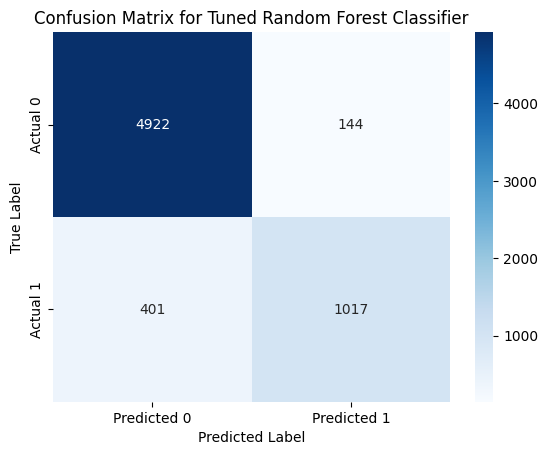


--- Classification Report for Tuned Random Forest ---
                 precision    recall  f1-score   support

    Default (0)       0.92      0.97      0.95      5066
Non-Default (1)       0.88      0.72      0.79      1418

       accuracy                           0.92      6484
      macro avg       0.90      0.84      0.87      6484
   weighted avg       0.91      0.92      0.91      6484


--- ROC AUC Score for Tuned Random Forest ---
ROC AUC Score: 0.9224
Tuned Random Forest model evaluation complete.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

print("Evaluating Tuned Random Forest Classifier model...")

# Make predictions on the test set using the best estimator from GridSearchCV
y_pred_tuned_rf = best_rf_model.predict(X_test)
y_pred_proba_tuned_rf = best_rf_model.predict_proba(X_test)[:, 1] # Probability of class 1 (Non-Default)

print("\n--- Confusion Matrix for Tuned Random Forest ---")
cm_tuned_rf = confusion_matrix(y_test, y_pred_tuned_rf)
sns.heatmap(cm_tuned_rf, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Tuned Random Forest Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n--- Classification Report for Tuned Random Forest ---")
print(classification_report(y_test, y_pred_tuned_rf, target_names=['Default (0)', 'Non-Default (1)']))

print("\n--- ROC AUC Score for Tuned Random Forest ---")
# Calculate ROC AUC score
roc_auc_tuned_rf = roc_auc_score(y_test, y_pred_proba_tuned_rf)
print(f"ROC AUC Score: {roc_auc_tuned_rf:.4f}")

print("Tuned Random Forest model evaluation complete.")